In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif, mutual_info_classif

from ucimlrepo import fetch_ucirepo 
import matplotlib.pyplot as plt

# 1) Análise de Dados

In [3]:
# Busca do Dataset
rt_iot2022 = fetch_ucirepo(id=942)

# Seperação das features com a coluna Target
x = rt_iot2022.data.features
y = rt_iot2022.data.targets

In [4]:
df_iot2022 = pd.concat([x, y], axis=1)
target_column = y.columns[0]

print(f'Shape: {df_iot2022.shape}')
print(f'Target: {target_column}\n')

df_iot2022.head(5)

Shape: (123117, 84)
Target: Attack_type



,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,...,0.0,29729182.96,29729182.96,29729182.96,29729182.96,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,...,0.0,29855277.06,29855277.06,29855277.06,29855277.06,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,...,0.0,29842149.02,29842149.02,29842149.02,29842149.02,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,...,0.0,29913774.97,29913774.97,29913774.97,29913774.97,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,...,0.0,29814704.90,29814704.90,29814704.90,29814704.90,0.0,64240,26847,502,MQTT_Publish


In [5]:
# Recuperação das colunas numéricas
numeric_columns = df_iot2022.select_dtypes(include=np.number).columns.to_list()
print(len(numeric_columns))

81


In [6]:
# Verificação de Linhas Duplicadas
print(f'Linhas Duplicadas: {df_iot2022.duplicated().sum()}')
print(f'% Duplicadas: {df_iot2022.duplicated().mean() * 100:.2f}\n')

null_values = df_iot2022.isnull().sum()
percent = round(null_values/len(df_iot2022) * 100, 2)

df_null_values = pd.DataFrame({"nulos": null_values, "(%)": percent}).sort_values(by='nulos', ascending=False)

print(df_null_values[df_null_values['nulos'] > 0] if (null_values > 0).any() else 'Sem Valores Nulos')

Linhas Duplicadas: 5195
% Duplicadas: 4.22

Sem Valores Nulos


Identificação de Outliers

In [7]:
def outlier_detection(pd_series: pd.Series):
    """ 
    Detecção de Outliers através da diferença entre o terceiro e o primeiro qquartil 
    """
    Q1 = pd_series.quantile(0.25)
    Q3 = pd_series.quantile(0.75)
    IQR = Q3 - Q1 

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR) 

    return  int(((pd_series < lower_limit) | (pd_series > upper_limit)).sum())

In [8]:
outlier_iqr = df_iot2022[numeric_columns].apply(outlier_detection).sort_values(ascending=False)
percent_iqr = round(outlier_iqr/len(df_iot2022) * 100, 2)

df_outliers = pd.DataFrame(data={"qtd_outliers": outlier_iqr, "pct_outliers": percent_iqr})

print(df_outliers[df_outliers['qtd_outliers'] > 0])

                       qtd_outliers  pct_outliers
flow_pkts_payload.avg         38116         30.96
bwd_header_size_tot           33148         26.92
bwd_header_size_max           33137         26.92
flow_ACK_flag_count           33083         26.87
bwd_pkts_tot                  32364         26.29
...                             ...           ...
fwd_bulk_bytes                  246          0.20
fwd_bulk_rate                   246          0.20
fwd_bulk_packets                246          0.20
flow_ECE_flag_count              72          0.06
flow_CWR_flag_count              71          0.06

[75 rows x 2 columns]


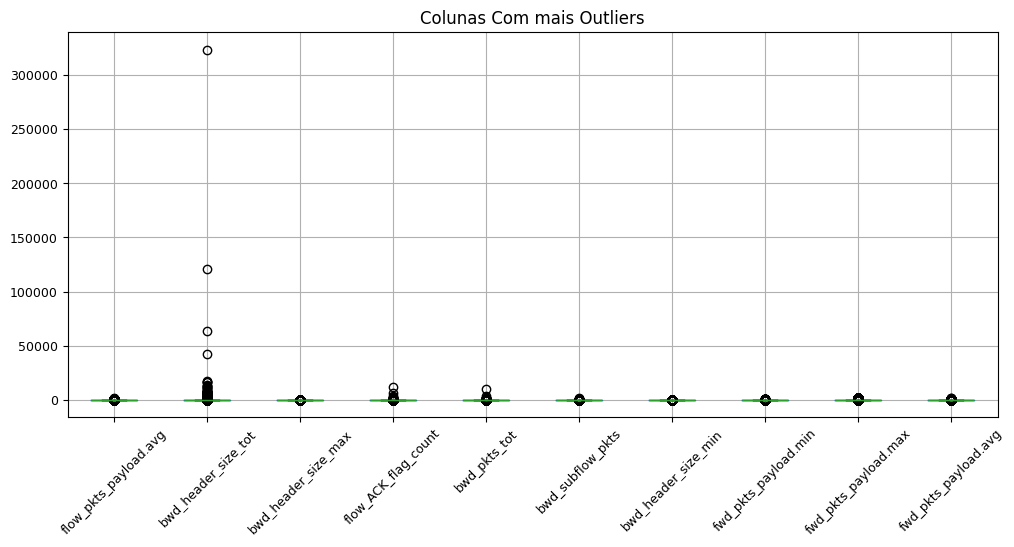

In [9]:
top_10_outliers = df_outliers.head(10).index

df_iot2022[top_10_outliers].boxplot(figsize=(12, 5), rot=45, fontsize=9)
plt.title("Colunas Com mais Outliers")
plt.show()

Distribuição das Classes

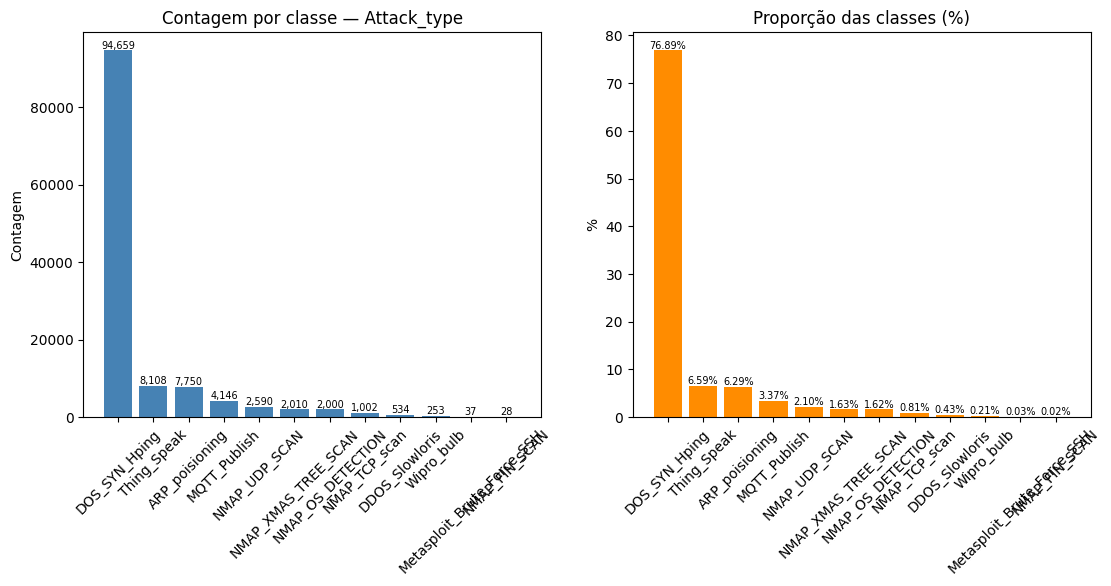

In [17]:
df_volumetry = df_iot2022[target_column].value_counts()
df_percent = round(df_iot2022[target_column].value_counts(normalize=True) * 100, 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))


axes[0].bar(df_volumetry.index.astype(str), df_volumetry.values, color='steelblue')
axes[0].set_title(f'Contagem por classe — {target_column}')
axes[0].set_ylabel('Contagem')
for i, v in enumerate(df_volumetry.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=7)
axes[0].tick_params(axis='x', rotation=45)



axes[1].bar(df_percent.index.astype(str), df_percent.values, color='darkorange')
axes[1].set_title('Proporção das classes (%)')
axes[1].set_ylabel('%')
for i, v in enumerate(df_percent.values):
    axes[1].text(i, v, f'{v:.2f}%', ha='center', va='bottom', fontsize=7)
axes[1].tick_params(axis='x', rotation=45)


plt.show()

In [ ]:
# Descrição das Colunas Numericas

df_iot2022[numeric_columns].describe()

,id.orig_p,id.resp_p,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,...,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size
count,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,1.231170e+05,1.231170e+05,1.231170e+05,...,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,123117.000000,123117.000000,123117.000000
mean,34639.258738,1014.305092,3.809566,2.268826,1.909509,1.471218,0.820260,3.518063e+05,3.517620e+05,7.035683e+05,...,1.481354e+05,2.353599e+04,1.616655e+06,1.701956e+06,3.517644e+06,1.664985e+06,4.550183e+04,6118.905123,2739.776018,751.647514
std,19070.620354,5256.371994,130.005408,22.336565,33.018311,19.635196,32.293948,3.707645e+05,3.708015e+05,7.415634e+05,...,1.613007e+06,1.477935e+06,8.809396e+06,9.252337e+06,1.229508e+08,9.007064e+06,1.091361e+06,18716.313861,10018.848534,6310.183843
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,17702.000000,21.000000,0.000001,1.000000,1.000000,1.000000,0.000000,7.454354e+01,7.288927e+01,1.490871e+02,...,9.536740e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
50%,37221.000000,21.000000,0.000004,1.000000,1.000000,1.000000,0.000000,2.467238e+05,2.467238e+05,4.934475e+05,...,4.053116e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
75%,50971.000000,21.000000,0.000005,1.000000,1.000000,1.000000,0.000000,5.242880e+05,5.242880e+05,1.048576e+06,...,5.006790e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
max,65535.000000,65389.000000,21728.335580,4345.000000,10112.000000,4345.000000,10105.000000,1.048576e+06,1.048576e+06,2.097152e+06,...,4.374931e+08,4.774862e+08,3.000000e+08,3.000000e+08,2.096777e+10,3.000000e+08,1.208029e+08,65535.000000,65535.000000,65535.000000


In [43]:
print(df_iot2022['Attack_type'].value_counts())
print(df_iot2022['Attack_type'].value_counts(normalize=True).multiply(100).round(2))

Attack_type
DOS_SYN_Hping                 94659
Thing_Speak                    8108
ARP_poisioning                 7750
MQTT_Publish                   4146
NMAP_UDP_SCAN                  2590
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  534
Wipro_bulb                      253
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    28
Name: count, dtype: int64
Attack_type
DOS_SYN_Hping                 76.89
Thing_Speak                    6.59
ARP_poisioning                 6.29
MQTT_Publish                   3.37
NMAP_UDP_SCAN                  2.10
NMAP_XMAS_TREE_SCAN            1.63
NMAP_OS_DETECTION              1.62
NMAP_TCP_scan                  0.81
DDOS_Slowloris                 0.43
Wipro_bulb                     0.21
Metasploit_Brute_Force_SSH     0.03
NMAP_FIN_SCAN                  0.02
Name: proportion, dtype: float64


# 2) Correlação com as outras colunas

Avaliar o quanto cada coluna se correlaciona com a multiclasse AttackType

In [18]:
[x for x in df_iot2022.columns if x not in numeric_columns]

['proto', 'service', 'Attack_type']

In [ ]:
df_correlation = pd.get_dummies(data=df_iot2022, columns=['proto', 'service'], drop_first=True)

df_numeric_correlation = df_correlation.select_dtypes(include=np.number).columns.to_list()
X_numeric = df_correlation[df_numeric_correlation]

encoding = LabelEncoder()
y_encoded = encoding.fit_transform(df_iot2022['Attack_type'])

In [ ]:
# Comparar as médias de 3 ou mais grupos e avaliar se uma das médias é diferente das outras
f_scores, p_class = f_classif(X=X_numeric, y=y_encoded)

c:\Users\rpf97\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [24] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
c:\Users\rpf97\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


[1.88765818e+03 8.28644352e+03 5.36760587e+02 4.43429197e+02
 6.31136801e+01 2.95300040e+02 4.29482947e+01 3.25594372e+03
 3.25929867e+03 3.25764783e+03 2.71498646e+03 5.61561476e+02
 1.13965750e+04 8.02617888e+03 5.08266073e+01 4.27322729e+03
 4.94209044e+03 6.76429252e+03 9.29836607e+03 6.10958426e+03
 5.97374774e+02 3.45390541e+02 1.30021695e+02 5.52084007e+06
            nan 1.34815651e+02 2.06010925e+02 1.64214472e+05
 1.98952923e+03 1.58230934e+02 2.35767774e+04 2.71066930e+03
 4.03003454e+03 5.35137406e+03 1.11155917e+01 5.27257169e+03
 5.03172182e+03 4.85729862e+02 3.47073479e+03 1.72660563e+01
 3.00392484e+03 2.00741394e+03 5.03086000e+00 2.00540585e+04
 5.36780086e+02 3.42399789e+03 1.69086588e+04 5.88347395e+01
 9.81957436e+02 2.71722635e+02 7.48598649e+02 7.62979148e+02
 3.36802503e+01 1.97583535e+04 5.36950479e+02 7.16442870e+03
 1.64114189e+04 3.75033717e+03 2.99869548e+03 3.65731794e+02
 4.63968378e+02 5.61912693e+01 1.47212954e+01 4.90813022e+00
 3.07097124e+01 5.697119

In [ ]:
# Informação Mútua
mi_scores = mutual_info_classif(X_numeric, y_encoded, discrete_features=False, random_state=42)
print(mi_scores)

In [46]:
df_scores = pd.DataFrame({
    "feature": X_numeric.columns,
    "f_score": f_scores,
    "p_value": p_class,
    "mi": mi_scores
}).sort_values('f_score', ascending=False)

df_scores.head(10)

,feature,f_score,p_value,mi
23,fwd_URG_flag_count,5.520840e+06,0.0,0.082397
27,fwd_pkts_payload.min,1.642145e+05,0.0,0.687369
80,fwd_last_window_size,5.640489e+04,0.0,0.768491
73,idle.min,2.377376e+04,0.0,0.173199
30,fwd_pkts_payload.avg,2.357678e+04,0.0,0.863119
76,idle.avg,2.168906e+04,0.0,0.173470
78,fwd_init_window_size,2.086841e+04,0.0,0.700307
43,fwd_iat.max,2.005406e+04,0.0,0.496456
53,flow_iat.max,1.975835e+04,0.0,0.670723
74,idle.max,1.937172e+04,0.0,0.174021


In [ ]:
# Avaliar as distribuição Top 1 por classe

top_feature = df_scores.iloc[0]['feature']

df_iot2022.groupby("Attack_type")[top_feature].agg(['mean','std','min','max','count'])

,mean,std,min,max,count
Attack_type,,,,,
ARP_poisioning,0.00000,0.000000,0,0,7750
DDOS_Slowloris,0.00000,0.000000,0,0,534
DOS_SYN_Hping,0.00000,0.000000,0,0,94659
MQTT_Publish,0.00000,0.000000,0,0,4146
Metasploit_Brute_Force_SSH,0.00000,0.000000,0,0,37
NMAP_FIN_SCAN,0.00000,0.000000,0,0,28
NMAP_OS_DETECTION,0.00000,0.000000,0,0,2000
NMAP_TCP_scan,0.00000,0.000000,0,0,1002
NMAP_UDP_SCAN,0.00000,0.000000,0,0,2590


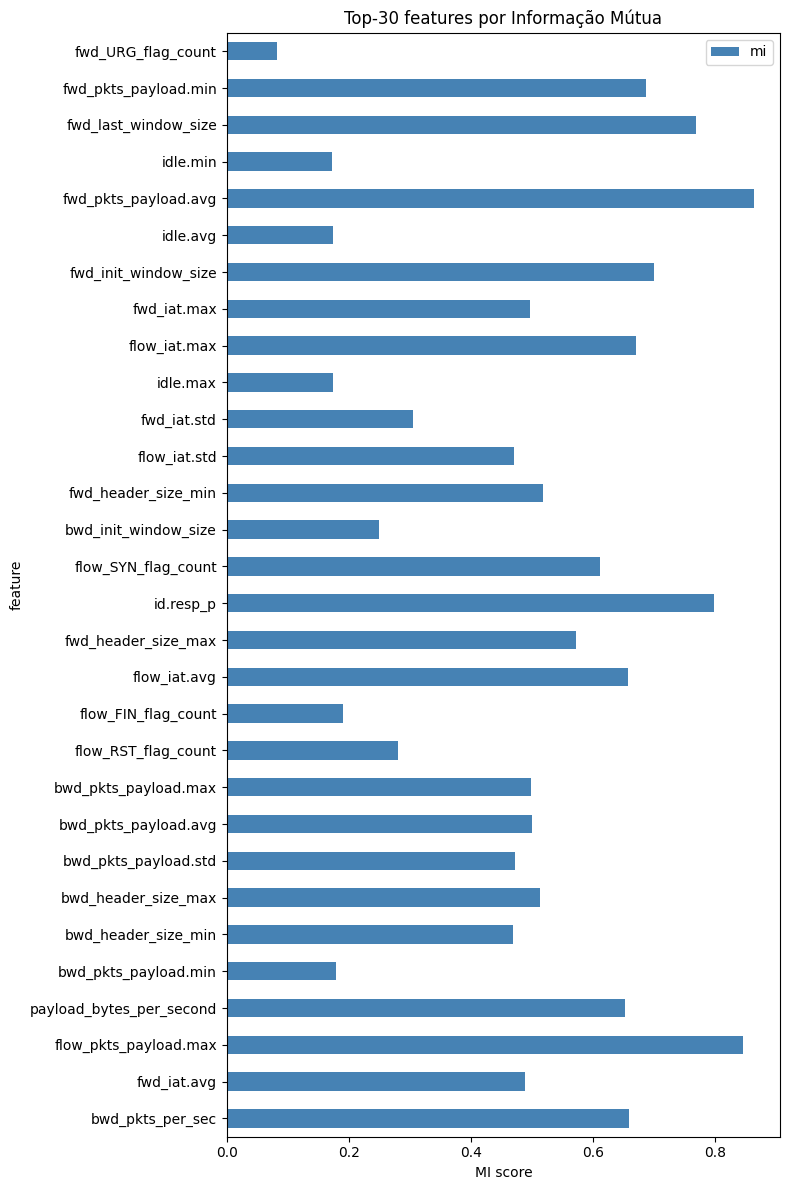

In [ ]:
fig, ax = plt.subplots(figsize=(8, 12))

df_scores.head(30).iloc[::-1].plot.barh(
    x='feature', y='mi', ax=ax, color='steelblue'
)
ax.set_title('Top-30 features por Mi-Score')
ax.set_xlabel('MI score')
plt.tight_layout()
plt.show()


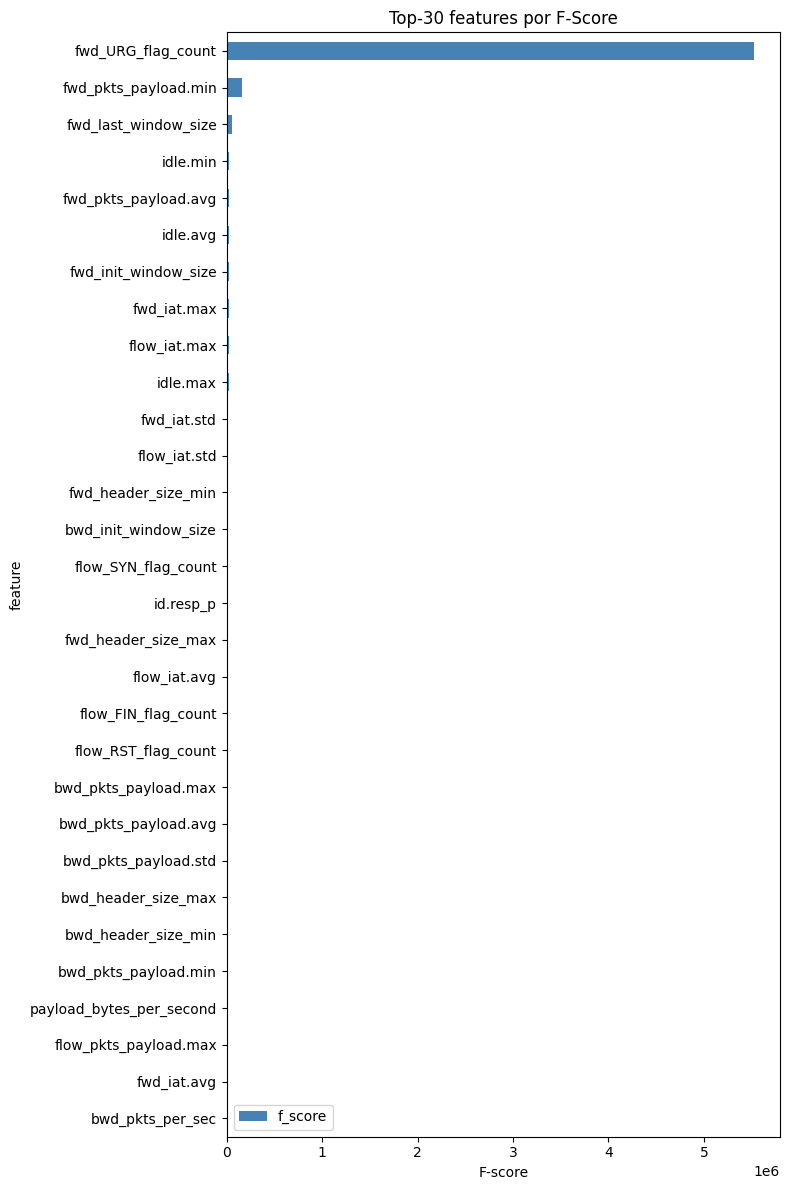

In [53]:
fig, ax = plt.subplots(figsize=(8, 12))

df_scores.head(30).iloc[::-1].plot.barh(
    x='feature', y='f_score', ax=ax, color='steelblue'
)
ax.set_title('Top-30 features por F-Score')
ax.set_xlabel('F-score')
plt.tight_layout()
plt.show()


In [ ]:
fig, ax = plt.subplots(figsize=(8, 12))

df_scores.head(30).iloc[::-1].plot.barh(
    x='feature', y='p_value', ax=ax, color='steelblue'
)
ax.set_title('Top-30 features por P-Value')
ax.set_xlabel('P-Value')
plt.tight_layout()
plt.show()


In [41]:
dup_index = df_iot2022.duplicated(keep=False)
groups = df_iot2022[dup_index].groupby(list(df_iot2022.columns[:-1]))

print("Grupos com rótulos diferentes:", (groups['Attack_type'].nunique() > 1).sum())


Grupos com rótulos diferentes: 3
